In [1]:
# ============================================================
# CELL 1: Imports + Dataset Preprocessing
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# ============================================================
# 1. Load dataset
# ============================================================

from pathlib import Path

DATA_PATH = Path("data/synthetic_data_improved.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/synthetic_data_improved.csv")
data = pd.read_csv(DATA_PATH)

print("Original dataset shape:", data.shape)


# ============================================================
# 2. Basic preprocessing
# ============================================================

# Remove time column
if 'time' in data.columns:
    data = data.drop(columns=['time'])

# Remove rows containing missing values
data = data.dropna()

print("After removing missing values:", data.shape)


# ============================================================
# 3. Outlier removal
# ============================================================

d50_limit = data['d50'].quantile(0.99)
sigma2_limit = data['sigma2'].quantile(0.99)

data = data[
    (data['d50'] < d50_limit) &
    (data['sigma2'] < sigma2_limit)
]

print("After outlier removal:", data.shape)


# ============================================================
# 4. Define input features
# ============================================================

features = [
    'S',
    'ub',
    'np',
    'T',
    'a676_a650',
    'a450_a676',
    'chl_a',
    'u'
]

X = data[features]

# Target variables
y_d50 = data['d50']
y_sigma2 = data['sigma2']


print("\nInput features:")
print(features)

print("\nNumber of features:", len(features))
print("Number of samples:", len(data))


# ============================================================
# 5. Train-test split
# ============================================================

X_train, X_test, y_train_d50, y_test_d50 = train_test_split(
    X,
    y_d50,
    test_size=0.30,
    random_state=42
)

X_train2, X_test2, y_train_sigma2, y_test_sigma2 = train_test_split(
    X,
    y_sigma2,
    test_size=0.30,
    random_state=42
)


# ============================================================
# 6. Dataset information
# ============================================================

print("\nDataset split")
print("----------------------------")
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))
print("Training features:", X_train.shape[1])
print("Testing features :", X_test.shape[1])

Original dataset shape: (1648, 11)
After removing missing values: (1402, 10)
After outlier removal: (1384, 10)

Input features:
['S', 'ub', 'np', 'T', 'a676_a650', 'a450_a676', 'chl_a', 'u']

Number of features: 8
Number of samples: 1384

Dataset split
----------------------------
Training samples: 968
Testing samples : 416
Training features: 8
Testing features : 8


In [2]:
# ============================================================
# CELL 2: Feature Importance (8 → Top 4)
# ============================================================

# Random Forest for feature importance
rf_importance = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train using all 8 features
rf_importance.fit(X_train, y_train_d50)

# Create feature importance table
importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_importance.feature_importances_
})

# Sort from highest to lowest
importance = importance.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("Feature Importance")
print("----------------------------")
display(importance)


# ============================================================
# Select Top 4 Features
# ============================================================

top4 = ['S', 'ub', 'np', 'T']

print("\nSelected Top 4 Features:")
print(top4)


# Create Top-4 datasets
Xtr_d50 = X_train[top4]
Xte_d50 = X_test[top4]

Xtr_sigma2 = X_train2[top4]
Xte_sigma2 = X_test2[top4]

print("\nTop-4 feature dataset shapes")
print("----------------------------")
print("d50 training :", Xtr_d50.shape)
print("d50 testing  :", Xte_d50.shape)
print("sigma2 training:", Xtr_sigma2.shape)
print("sigma2 testing :", Xte_sigma2.shape)

Feature Importance
----------------------------


,Feature,Importance
0,ub,0.586629
1,S,0.280805
2,T,0.050159
3,chl_a,0.024365
4,np,0.018140
5,u,0.013830
6,a676_a650,0.013378
7,a450_a676,0.012692



Selected Top 4 Features:
['S', 'ub', 'np', 'T']

Top-4 feature dataset shapes
----------------------------
d50 training : (968, 4)
d50 testing  : (416, 4)
sigma2 training: (968, 4)
sigma2 testing : (416, 4)


In [3]:
# ============================================================
# CELL 3: Random Forest Regression
# ============================================================

rf_d50 = RandomForestRegressor(
    n_estimators=400,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    oob_score=True,
    n_jobs=-1
)

rf_sigma2 = RandomForestRegressor(
    n_estimators=400,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    oob_score=True,
    n_jobs=-1
)


# ============================================================
# Train
# ============================================================

rf_d50.fit(
    Xtr_d50,
    y_train_d50
)

rf_sigma2.fit(
    Xtr_sigma2,
    y_train_sigma2
)


# ============================================================
# Predict
# ============================================================

y_pred_d50_rf = rf_d50.predict(Xte_d50)

y_pred_sigma2_rf = rf_sigma2.predict(Xte_sigma2)


# ============================================================
# R²
# ============================================================

r2_d50_rf = r2_score(
    y_test_d50,
    y_pred_d50_rf
)

r2_sigma2_rf = r2_score(
    y_test_sigma2,
    y_pred_sigma2_rf
)


print("Random Forest Results")
print("----------------------------")

print(f"RF R² (d50)    : {r2_d50_rf:.6f}")
print(f"RF R² (sigma²) : {r2_sigma2_rf:.6f}")


# ============================================================
# OOB Scores
# ============================================================

print("\nOOB Scores")
print("----------------------------")

print(f"d50    : {rf_d50.oob_score_:.6f}")
print(f"sigma² : {rf_sigma2.oob_score_:.6f}")

Random Forest Results
----------------------------
RF R² (d50)    : 0.839727
RF R² (sigma²) : 0.904587

OOB Scores
----------------------------
d50    : 0.843463
sigma² : 0.898851


In [4]:
# ============================================================
# CELL 4: Support Vector Regression (SVR)
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV


# ============================================================
# 1. SVR Pipeline
# ============================================================

svr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR(kernel='rbf'))
])


# ============================================================
# 2. Hyperparameter Grid
# ============================================================

param_grid = {
    'svr__C': [1, 10, 100, 500, 1000, 2000],
    'svr__epsilon': [0.1, 0.5, 1, 2]
}


# ============================================================
# 3. Grid Search for d50
# ============================================================

grid_d50 = GridSearchCV(
    estimator=svr_pipe,
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    n_jobs=1
)

grid_d50.fit(
    Xtr_d50,
    y_train_d50
)


# ============================================================
# 4. Grid Search for sigma²
# ============================================================

grid_sigma2 = GridSearchCV(
    estimator=svr_pipe,
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    n_jobs=1
)

grid_sigma2.fit(
    Xtr_sigma2,
    y_train_sigma2
)


# ============================================================
# 5. Best Models
# ============================================================

svr_d50 = grid_d50.best_estimator_
svr_sigma2 = grid_sigma2.best_estimator_


# ============================================================
# 6. Best Parameters
# ============================================================

print("Best Parameters")
print("----------------------------")
print("d50    :", grid_d50.best_params_)
print("sigma² :", grid_sigma2.best_params_)


# ============================================================
# 7. Predictions
# ============================================================

y_pred_d50_svr = svr_d50.predict(Xte_d50)
y_pred_sigma2_svr = svr_sigma2.predict(Xte_sigma2)


# ============================================================
# 8. R²
# ============================================================

r2_d50_svr = r2_score(
    y_test_d50,
    y_pred_d50_svr
)

r2_sigma2_svr = r2_score(
    y_test_sigma2,
    y_pred_sigma2_svr
)


# ============================================================
# 9. Results
# ============================================================

print("\nSVR Results")
print("----------------------------")
print(f"SVR R² (d50)    : {r2_d50_svr:.6f}")
print(f"SVR R² (sigma²) : {r2_sigma2_svr:.6f}")

Best Parameters
----------------------------
d50    : {'svr__C': 100, 'svr__epsilon': 2}
sigma² : {'svr__C': 100, 'svr__epsilon': 2}

SVR Results
----------------------------
SVR R² (d50)    : 0.854116
SVR R² (sigma²) : 0.914782


In [5]:
# ============================================================
# CELL 5: XGBoost Regression
# ============================================================

from xgboost import XGBRegressor

# ============================================================
# 1. XGBoost model for d50
# ============================================================

xgb_d50 = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=1
)

# Train
xgb_d50.fit(
    Xtr_d50,
    y_train_d50
)

# Predict
y_pred_d50_xgb = xgb_d50.predict(
    Xte_d50
)

# ============================================================
# 2. XGBoost model for sigma²
# ============================================================

xgb_sigma2 = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=1
)

# Train
xgb_sigma2.fit(
    Xtr_sigma2,
    y_train_sigma2
)

# Predict
y_pred_sigma2_xgb = xgb_sigma2.predict(
    Xte_sigma2
)

# ============================================================
# 3. Calculate R²
# ============================================================

r2_d50_xgb = r2_score(
    y_test_d50,
    y_pred_d50_xgb
)

r2_sigma2_xgb = r2_score(
    y_test_sigma2,
    y_pred_sigma2_xgb
)

# ============================================================
# 4. Results
# ============================================================

print("XGBoost Results")
print("----------------------------")
print(f"XGBoost R² (d50)    : {r2_d50_xgb:.6f}")
print(f"XGBoost R² (sigma²) : {r2_sigma2_xgb:.6f}")

XGBoost Results
----------------------------
XGBoost R² (d50)    : 0.849638
XGBoost R² (sigma²) : 0.913948


In [6]:
# ============================================================
# CELL 6: Model Evaluation - R², RMSE, MAE
# ============================================================

# ============================================================
# 1. Evaluation function
# ============================================================

def evaluate_model(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)

    return r2, rmse, mae


# ============================================================
# 2. Random Forest Metrics
# ============================================================

rf_d50_metrics = evaluate_model(
    y_test_d50,
    y_pred_d50_rf
)

rf_sigma2_metrics = evaluate_model(
    y_test_sigma2,
    y_pred_sigma2_rf
)


# ============================================================
# 3. SVR Metrics
# ============================================================

svr_d50_metrics = evaluate_model(
    y_test_d50,
    y_pred_d50_svr
)

svr_sigma2_metrics = evaluate_model(
    y_test_sigma2,
    y_pred_sigma2_svr
)


# ============================================================
# 4. XGBoost Metrics
# ============================================================

xgb_d50_metrics = evaluate_model(
    y_test_d50,
    y_pred_d50_xgb
)

xgb_sigma2_metrics = evaluate_model(
    y_test_sigma2,
    y_pred_sigma2_xgb
)


# ============================================================
# 5. Print Results
# ============================================================

print("MODEL EVALUATION RESULTS")
print("=" * 60)

print("\nRandom Forest")
print("----------------------------")
print(f"d50    → R²: {rf_d50_metrics[0]:.6f}, "
      f"RMSE: {rf_d50_metrics[1]:.6f}, "
      f"MAE: {rf_d50_metrics[2]:.6f}")

print(f"sigma² → R²: {rf_sigma2_metrics[0]:.6f}, "
      f"RMSE: {rf_sigma2_metrics[1]:.6f}, "
      f"MAE: {rf_sigma2_metrics[2]:.6f}")


print("\nSVR")
print("----------------------------")
print(f"d50    → R²: {svr_d50_metrics[0]:.6f}, "
      f"RMSE: {svr_d50_metrics[1]:.6f}, "
      f"MAE: {svr_d50_metrics[2]:.6f}")

print(f"sigma² → R²: {svr_sigma2_metrics[0]:.6f}, "
      f"RMSE: {svr_sigma2_metrics[1]:.6f}, "
      f"MAE: {svr_sigma2_metrics[2]:.6f}")


print("\nXGBoost")
print("----------------------------")
print(f"d50    → R²: {xgb_d50_metrics[0]:.6f}, "
      f"RMSE: {xgb_d50_metrics[1]:.6f}, "
      f"MAE: {xgb_d50_metrics[2]:.6f}")

print(f"sigma² → R²: {xgb_sigma2_metrics[0]:.6f}, "
      f"RMSE: {xgb_sigma2_metrics[1]:.6f}, "
      f"MAE: {xgb_sigma2_metrics[2]:.6f}")

MODEL EVALUATION RESULTS

Random Forest
----------------------------
d50    → R²: 0.839727, RMSE: 15.769391, MAE: 12.557029
sigma² → R²: 0.904587, RMSE: 7.931282, MAE: 6.251181

SVR
----------------------------
d50    → R²: 0.854116, RMSE: 15.044842, MAE: 11.969561
sigma² → R²: 0.914782, RMSE: 7.495579, MAE: 5.801557

XGBoost
----------------------------
d50    → R²: 0.849638, RMSE: 15.274025, MAE: 12.284159
sigma² → R²: 0.913948, RMSE: 7.532165, MAE: 5.880333


In [7]:
# ============================================================
# CELL 7: Model Comparison Table
# ============================================================

comparison = pd.DataFrame({
    'Model': [
        'Random Forest',
        'SVR',
        'XGBoost'
    ],

    'd50 R²': [
        rf_d50_metrics[0],
        svr_d50_metrics[0],
        xgb_d50_metrics[0]
    ],

    'd50 RMSE': [
        rf_d50_metrics[1],
        svr_d50_metrics[1],
        xgb_d50_metrics[1]
    ],

    'd50 MAE': [
        rf_d50_metrics[2],
        svr_d50_metrics[2],
        xgb_d50_metrics[2]
    ],

    'σ² R²': [
        rf_sigma2_metrics[0],
        svr_sigma2_metrics[0],
        xgb_sigma2_metrics[0]
    ],

    'σ² RMSE': [
        rf_sigma2_metrics[1],
        svr_sigma2_metrics[1],
        xgb_sigma2_metrics[1]
    ],

    'σ² MAE': [
        rf_sigma2_metrics[2],
        svr_sigma2_metrics[2],
        xgb_sigma2_metrics[2]
    ]
})

# Round values for clean display
comparison = comparison.round(6)

print("FINAL MODEL COMPARISON")
print("=" * 100)

display(comparison)

FINAL MODEL COMPARISON


,Model,d50 R²,d50 RMSE,d50 MAE,σ² R²,σ² RMSE,σ² MAE
0,Random Forest,0.839727,15.769391,12.557029,0.904587,7.931282,6.251181
1,SVR,0.854116,15.044842,11.969561,0.914782,7.495579,5.801557
2,XGBoost,0.849638,15.274025,12.284159,0.913948,7.532165,5.880333


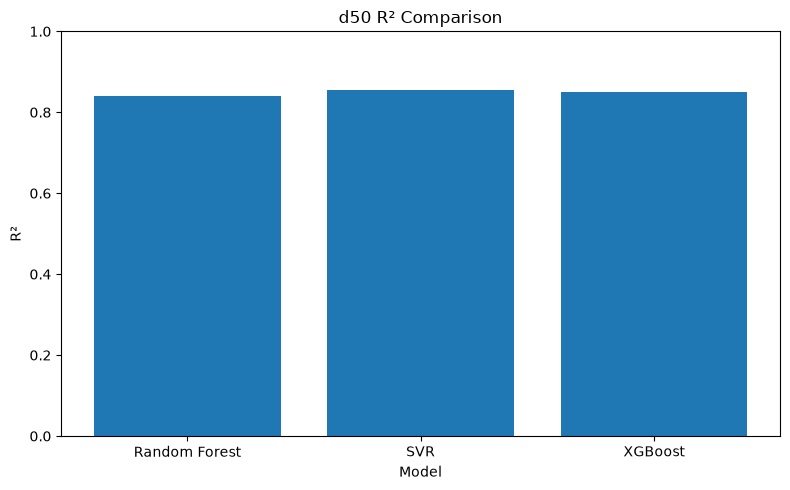

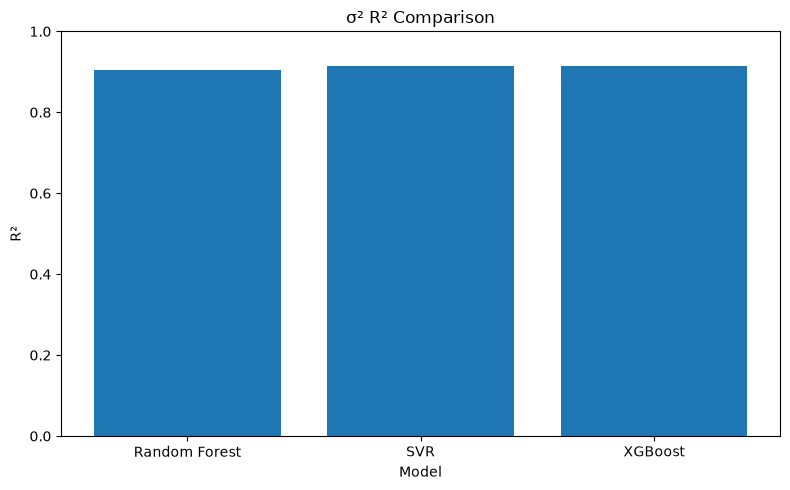

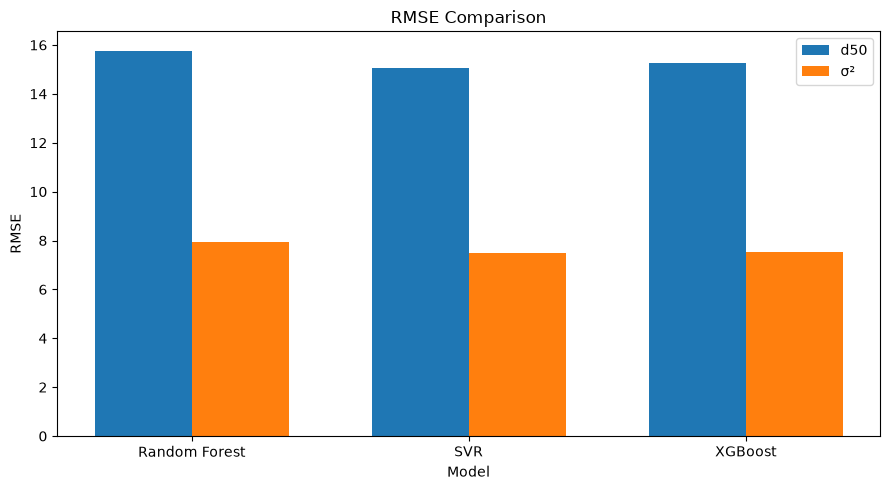

In [8]:
# ============================================================
# CELL 8: Model Comparison Graphs
# ============================================================

import matplotlib.pyplot as plt

models = comparison['Model']

# ============================================================
# 1. R² Comparison - d50
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    models,
    comparison['d50 R²']
)

plt.ylabel('R²')
plt.xlabel('Model')
plt.title('d50 R² Comparison')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


# ============================================================
# 2. R² Comparison - sigma²
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    models,
    comparison['σ² R²']
)

plt.ylabel('R²')
plt.xlabel('Model')
plt.title('σ² R² Comparison')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


# ============================================================
# 3. RMSE Comparison
# ============================================================

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    comparison['d50 RMSE'],
    width,
    label='d50'
)

plt.bar(
    x + width/2,
    comparison['σ² RMSE'],
    width,
    label='σ²'
)

plt.xticks(x, models)
plt.ylabel('RMSE')
plt.xlabel('Model')
plt.title('RMSE Comparison')
plt.legend()

plt.tight_layout()
plt.show()